# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
# pyright: reportAttributeAccessIssue=false, reportArgumentType=false, reportCallIssue=false
# (заглушки типів pandas/geopandas не знають, що в колонці geometry лежать геометрії,
#  тому Pylance підкреслює робочий код червоним - вимикаю саме ці перевірки)
STUDENT_NAME = 'Козак Наталія Володимирівна'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 6      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 6: Чернівці, Україна


Мій варіант - №6, місто **Чернівці** (взято зі списку автоматично, викладач іншого не призначав).

> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing and importlib.util.find_spec('pip') is not None:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
elif missing:
    # у моєму venv (uv) немає pip, тому пакети ставлю через uv, а не з ноутбука
    print('бракує пакетів:', ', '.join(missing))
    print('встановити в терміналі: cd ~/University && uv add', ' '.join(missing))
    print('після цього перезапустити ядро')
else:
    print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

# головний сервер Overpass часто перевантажений (502/504), тому при живому запиті
# пробую дзеркала по черзі з паузою, що зростає (ті самі дзеркала, що у fetch_city_osm.py)
MIRRORS = ['https://overpass-api.de/api',
           'https://overpass.private.coffee/api',
           'https://z.overpass-api.de/api']


def with_retry(getter, rounds=5, pause=20):
    last = None
    for r in range(rounds):
        for url in MIRRORS:
            ox.settings.overpass_url = url
            try:
                return getter()
            except Exception as e:      # 502/504/429, обрив з'єднання
                last = e
                print('  %s: %s, пробую далі' % (url.split('/')[2], type(e).__name__))
        print('  усі дзеркала зайняті, чекаю %d с' % (pause * 2 ** r))
        time.sleep(pause * 2 ** r)
    raise RuntimeError('усі дзеркала Overpass зайняті') from last


TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_чернівці


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено - читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # живий запит: міряю час і приріст кешу osmnx (туди лягають сирі відповіді сервера)
    t0, b0 = time.time(), cache_bytes()
    g = clean(with_retry(getter))
    g.to_parquet(path, index=False)
    g = gpd.read_parquet(path)          # читаю назад, щоб типи були такі самі, як у знімка
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    save_live_cost(name, COST[name])
    return g


def save_live_cost(name, row):
    """Живий запит іде лише при першому запуску, тому його вартість зберігаю у файл -
    інакше при повторному запуску не буде з чим порівняти знімок."""
    p = os.path.join(OUT, 'live_cost.json')
    live = json.load(open(p, encoding='utf-8')) if os.path.exists(p) else {}
    live[name] = row
    with open(p, 'w', encoding='utf-8') as f:
        json.dump(live, f, ensure_ascii=False, indent=1)

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 151.4 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = with_retry(lambda: ox.graph_from_polygon(poly, network_type='walk'))
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 14284 | ребер 38050


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

# мережу качає окрема гілка в комірці вище, тож її живу вартість дописую тут
if COST['мережа walk']['спосіб'] == 'живий запит':
    save_live_cost('мережа walk', COST['мережа walk'])
LIVE_P = os.path.join(OUT, 'live_cost.json')
live = json.load(open(LIVE_P, encoding='utf-8')) if os.path.exists(LIVE_P) else {}

snap_rows = {k: v for k, v in COST.items() if v['спосіб'] == 'знімок'}
common = [k for k in COST if k in live and k in snap_rows]
if common:
    cmp_cost = pd.DataFrame({
        'живий, с':     [live[k]['секунд'] for k in common],
        'живий, МБ':    [live[k]['передано_МБ'] for k in common],
        'знімок, с':    [snap_rows[k]['секунд'] for k in common],
        'файл, МБ':     [snap_rows[k]['файл_МБ'] for k in common]}, index=common)
    display(cmp_cost)
    T_LIVE, T_SNAP = cmp_cost['живий, с'].sum(), max(cmp_cost['знімок, с'].sum(), 1e-3)
    MB_SAVED = cmp_cost['живий, МБ'].sum()
    print('живий запит усіх шарів: %.1f с, знімок: %.2f с - швидше в ~%.0f разів'
          % (T_LIVE, T_SNAP, T_LIVE / T_SNAP))
    print('при повторному запуску не передано мережею: %.2f МБ' % MB_SAVED)
else:
    T_LIVE = T_SNAP = MB_SAVED = float('nan')
    print('це перший запуск: вартість живого запиту записана в', LIVE_P,
          '- порівняння буде видно при повторному запуску')

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.034,0.092
heritage,знімок,93,0.0,0.046,0.059
stations,знімок,8,0.0,0.032,0.063
amenities,знімок,294,0.0,0.064,0.069
мережа walk,знімок,52334,0.0,2.953,0.161


,"живий, с","живий, МБ","знімок, с","файл, МБ"
boundary,1.8,0.035,0.092,0.034
heritage,85.4,0.045,0.059,0.046
stations,161.6,0.012,0.063,0.032
amenities,169.5,0.090,0.069,0.064
мережа walk,177.5,7.105,0.161,2.953


живий запит усіх шарів: 595.8 с, знімок: 0.44 с - швидше в ~1342 разів
при повторному запуску не передано мережею: 7.29 МБ


> Живий запит робився один раз (перший запуск), далі всі шари читаються зі знімка.
> Вартість живого запиту збережена в `live_cost.json`, тому друга таблиця показує обидва способи поруч.

> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
# Перевірка CRS: для метрів беру UTM. Для цього міста geopandas сам оцінює зону -
# якщо вийде 32635, то всі to_crs(32635) нижче правильні.
print('оцінена UTM-зона для міста:', boundary.estimate_utm_crs().to_epsg())

has_hist = heritage['historic'].notna() & (heritage['historic'] != 'no')
has_tour = heritage['tourism'].isin(TOURISM_OK)
mask = has_hist | has_tour                       # об'єднання, а не перетин
has_name = heritage['name'].notna() & (heritage['name'].str.strip() != '')
cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('  лише historic        :', int((has_hist & ~has_tour & has_name).sum()))
print('  лише tourism         :', int((~has_hist & has_tour & has_name).sum()))
print('  обидва               :', int((has_hist & has_tour & has_name).sum()))

# що саме відкинуто і чому
dropped = heritage[~(mask & has_name)].copy()
dropped['причина'] = np.where(~mask[dropped.index], 'не ті теги', 'немає name')
dropped['тип'] = dropped['historic'].fillna('tourism=' + dropped['tourism'].fillna('?'))
print()
print('відкинуто: %d об’єктів' % len(dropped))
print(dropped.groupby(['причина', 'тип']).size().sort_values(ascending=False).to_string())
rp_d = dropped.geometry.representative_point()
dropped['lat'], dropped['lon'] = rp_d.y.round(5), rp_d.x.round(5)
cols = ['element', 'id', 'тип', 'memorial', 'description', 'lat', 'lon']
print()
print(dropped[[c for c in cols if c in dropped.columns]].to_string(index=False))

оцінена UTM-зона для міста: 32635
усього у шарі heritage : 93
підходять за тегами    : 93
з них мають name       : 72
  лише historic        : 40
  лише tourism         : 31
  обидва               : 1

відкинуто: 21 об’єктів
причина     тип               
немає name  memorial              7
            tourism=attraction    5
            railway_car           4
            monument              2
            tomb                  1
            tourism=artwork       1
            tourism=viewpoint     1

element          id                тип memorial description      lat      lon
   node   472301787           memorial      NaN         NaN 48.29333 25.95655
   node  1714965215           memorial      NaN         NaN 48.35663 25.95573
   node  1715140196           memorial      NaN         NaN 48.34149 25.95948
   node  1787004883           memorial      NaN         NaN 48.29040 25.95653
   node  3414057683 tourism=attraction      NaN         NaN 48.28927 25.93654
   node  3733016389    

In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial          32
monument           6
castle             1
church             1
wayside_shrine     1

=== tourism ===
tourism
museum        12
attraction    12
artwork        4
viewpoint      3
gallery        1

типи геометрії: {'Point': 68, 'Polygon': 4}


**Що відкинуто.** Запит до Overpass уже був за тегами `historic=*` або `tourism` з переліку,
тому за тегами нічого не відпало - усе відкинуте відпало через відсутність `name`.
Серед типів геометрії є і `Point`, і `Polygon`, тобто пам'ятники та меморіали (вузли) не втрачені.
Конкретні числа і перелік відкинутих - у виводі вище та у звіті (питання 1).

> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

Ваги рейтингу задані в словнику `WEIGHTS` на початку наступної комірки. Двом пам'ятникам сигнал wiki не зараховано, бо їхній wikidata веде на інший об'єкт (обґрунтування - у звіті, питання 2 і 7).


In [12]:
# ===== ВАГИ РЕЙТИНГУ =====
WEIGHTS = {
    'wiki':     0.35,   # є wikidata або wikipedia
    'n_lang':   0.25,   # скільки мовами перекладено назву (частка рангу)
    'museum':   0.20,   # tourism = museum / gallery
    'historic': 0.10,   # заповнений historic
    'area':     0.10,   # площа полігона (частка рангу), найслабший сигнал
}
# =====================================================

metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

name_cols = [c for c in cand.columns if c.startswith('name:')]
wiki_cols = [c for c in ['wikidata', 'wikipedia'] if c in cand.columns]
cand['wiki']     = cand[wiki_cols].notna().any(axis=1).astype(float)
# 2 хибні посилання: wikidata цих пам'ятників веде на парк / сквер, де вони стоять
# (перевірила на wikidata.org), тому сигнал wiki їм не зараховую
WIKI_WRONG = {('node', 1400237293): 'Q20083620 - Парк імені Юрія Федьковича',
              ('node', 2242145097): 'Q60174665 - сквер з рідкісними деревами'}
wrong = np.array([(e, int(i)) in WIKI_WRONG for e, i in zip(cand['element'], cand['id'])])
cand.loc[wrong, 'wiki'] = 0.0
WIKI_WRONG_NAMES = list(cand.loc[wrong, 'name'])
print('wiki прибрано через хибне посилання:', ', '.join(WIKI_WRONG_NAMES))
cand['n_lang']   = cand[name_cols].notna().sum(axis=1)
cand['museum']   = cand['tourism'].isin(['museum', 'gallery']).astype(float)
cand['hist']     = cand['historic'].notna().astype(float)

# усе до шкали 0..1: прапорці вже 0/1, неперервні - через частку рангу
signals = pd.DataFrame({
    'wiki':     cand['wiki'],
    'n_lang':   cand['n_lang'].rank(pct=True),
    'museum':   cand['museum'],
    'historic': cand['hist'],
    'area':     cand['area_m2'].rank(pct=True).where(cand['area_m2'] > 0, 0.0),
})
cand['score'] = sum(WEIGHTS[k] * signals[k] for k in WEIGHTS)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('музеї/галереї:', int(cand['museum'].sum()))
print('полігонів з площею > 0:', int((cand['area_m2'] > 0).sum()))
print('мов у назві  : медіана %.0f, максимум %d' % (cand['n_lang'].median(), cand['n_lang'].max()))
print('сума ваг     :', round(sum(WEIGHTS.values()), 3))
print()
print('внесок сигналів у бал (середнє по кандидатах):')
print((signals * pd.Series(WEIGHTS)).mean().round(3).to_string())

wiki прибрано через хибне посилання: Franz Josef, Пам'ятник Сидору Воробкевичу
кандидатів   : 72
мають wiki   : 5
музеї/галереї: 13
полігонів з площею > 0: 4
мов у назві  : медіана 1, максимум 6
сума ваг     : 1.0

внесок сигналів у бал (середнє по кандидатах):
wiki        0.024
n_lang      0.127
museum      0.036
historic    0.057
area        0.005


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

# стабільне сортування: при однаковому балі вирішує id OSM, щоб результат не залежав від випадку
cand = cand.sort_values('id', kind='mergesort').reset_index(drop=True)
top_score = cand.sort_values('score', ascending=False, kind='mergesort').head(N_LARGE).reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.sort_values('area_m2', ascending=False, kind='mergesort').head(N_SMALL).reset_index(drop=True)
overlap   = len(set(top10['id']) & set(top_naive['id']))
print('перетин: %d з %d' % (overlap, N_SMALL))
print('у рейтингу за площею об’єктів з площею > 0: %d з %d (решта - точки з площею 0, між ними порядок просто за id OSM)'
      % (int((top_naive['area_m2'] > 0).sum()), N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'бал': list(top10['score'].round(3)),
                      'за площею': list(top_naive['name']),
                      'площа, м²': list(top_naive['area_m2'].round(0))}))

# друга альтернатива для порівняння: ті самі сигнали, але всі ваги однакові
eq = sum(signals[k] for k in WEIGHTS) / len(WEIGHTS)
top_eq = cand.assign(eq=eq.values).sort_values('eq', ascending=False, kind='mergesort').head(N_SMALL)
overlap_eq = len(set(top10['id']) & set(top_eq['id']))
print('перетин з рейтингом "усі ваги однакові": %d з %d' % (overlap_eq, N_SMALL))
print('  топ-10 при однакових вагах:', ', '.join(top_eq['name']))

перетин: 4 з 10
у рейтингу за площею об’єктів з площею > 0: 4 з 10 (решта - точки з площею 0, між ними порядок просто за id OSM)


,за вашим критерієм,бал,за площею,"площа, м²"
0,Костел Воздвиження Святого Христа,0.788,Костел Воздвиження Святого Христа,1115.0
1,Музей Володимира Івасюка,0.757,Музей Буковинської Діаспори,473.0
2,Музей Буковинської Діаспори,0.742,Церква Покрови Пресвятої Діви Марії,167.0
3,Музей пожежно-рятувальної справи,0.644,Турецька криниця,85.0
4,Турецька криниця,0.540,Художній музей,0.0
5,Художній музей,0.438,Музей Народної Архітектури,0.0
6,Музей етнографії та стародавньої історії,0.438,Пам’ятник загиблим в Афганістані,0.0
7,Чернівецький літературно-меморіальний музей Ол...,0.407,Пам'ятник Юрію Федьковичу,0.0
8,Музей Авіації та Космонавтики,0.407,Краєзнавчий музей,0.0
9,Музей історії та культури євреїв Буковини,0.407,Пам'ятник Т.Г.Шевченку,0.0


перетин з рейтингом "усі ваги однакові": 2 з 10
  топ-10 при однакових вагах: Стадіон, Пожежна сирена, Пам'ятник Міхаю Емінеску, Мойсей Альтман, Козацький пагорб, Пожежна повозка, Костел Воздвиження Святого Христа, Пам'ятник Ользі Кобилянській, Пам'ятник Сидіру Воробкевичу, Музей етнографії та стародавньої історії


Рейтинг за площею в цьому місті майже не працює: полігонів серед кандидатів дуже мало,
решта точки з площею 0, і порядок між ними визначає просто id OSM (сортування стабільне), а не цінність.
Рейтинг з однаковими вагами теж дає зовсім інший список - тобто відповідь «найкращі» задають ваги, а не дані.

### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# спершу перевірка, що функція взагалі працює: дві точки ~30 м одна від одної
from shapely.geometry import Point
_t = gpd.GeoDataFrame(geometry=[Point(25.9350, 48.2920), Point(25.9354, 48.2920)], crs='EPSG:4326')
print('тест на близьких точках:', [(i, j, round(d, 1)) for i, j, d in close_pairs(_t)])

def show_pairs(gdf, label):
    pairs = close_pairs(gdf)
    print('\n%s: пар ближче 60 м - %d' % (label, len(pairs)))
    for i, j, d in pairs:
        a, b = gdf.iloc[i], gdf.iloc[j]
        print('  %5.1f м | %s (%s/%s, бал %.2f)  <->  %s (%s/%s, бал %.2f)'
              % (d, a['name'], a['element'], a['id'], a['score'], b['name'], b['element'], b['id'], b['score']))
    return pairs

pairs30 = show_pairs(top_score, 'top_score до чистки')

# Рішення: з пари лишаю об'єкт з вищим балом (він "представляє" обидва), другий видаляю,
# а на звільнене місце беру наступного кандидата. Роблю жадібно по всьому рейтингу,
# щоб і нові кандидати не стояли ближче 60 м до вже взятих.
order = cand.sort_values('score', ascending=False, kind='mergesort')
XYc = np.c_[order.to_crs(32635).geometry.representative_point().x,
            order.to_crs(32635).geometry.representative_point().y]
keep, removed = [], []
for pos, idx in enumerate(order.index):
    if len(keep) == N_LARGE:
        break
    near = [k for k in keep if np.hypot(*(XYc[pos] - XYc[order.index.get_loc(k)])) < 60]
    if near:
        removed.append((order.loc[idx, 'name'], order.loc[idx, 'id'], order.loc[near[0], 'name']))
    else:
        keep.append(idx)
print('\nвидалено як дублікат/частину сусіднього об’єкта:')
for n, i, by in removed:
    print('  %s (id %s) - поруч з "%s"' % (n, i, by))

top_score = order.loc[keep].reset_index(drop=True)
top10 = top_score.head(N_SMALL)
overlap = len(set(top10['id']) & set(top_naive['id']))
assert len(close_pairs(top_score)) == 0
print('\nпісля чистки: у top_score %d об’єктів, пар ближче 60 м - 0' % len(top_score))
print('перетин з рейтингом за площею після чистки: %d з %d' % (overlap, N_SMALL))

тест на близьких точках: [(0, 1, np.float64(29.7))]

top_score до чистки: пар ближче 60 м - 3
    4.9 м | Німецький будинок (node/6211071385, бал 0.21)  <->  Німецький будинок (node/8015932385, бал 0.21)
   45.0 м | Steinbarg (node/7916534188, бал 0.29)  <->  Вуличне мистецтво (node/8016556690, бал 0.21)
   54.1 м | Костел Воздвиження Святого Христа (way/32202686, бал 0.79)  <->  600 років моєму рідному місту (node/5173812303, бал 0.31)

видалено як дублікат/частину сусіднього об’єкта:
  600 років моєму рідному місту (id 5173812303) - поруч з "Костел Воздвиження Святого Христа"
  Німецький будинок (id 8015932385) - поруч з "Німецький будинок"
  Вуличне мистецтво (id 8016556690) - поруч з "Steinbarg"

після чистки: у top_score 30 об’єктів, пар ближче 60 м - 0
перетин з рейтингом за площею після чистки: 4 з 10


**Рішення щодо дублікатів:** з кожної пари ближче 60 м лишаю об'єкт з вищим балом,
другий видаляю, а його місце в топ-30 займає наступний кандидат (теж перевірений на 60 м).
Після чистки близьких пар у `top_score` нуль, `top10` взято вже з почищеного списку.

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 8
                            name  railway       building
0              Чернівці-Північна  station            NaN
1                       Чернівці  station            NaN
2                    Калинівська  station            NaN
3                        Садгора  station            NaN
4              Чернівці-Південна  station            NaN
5                            NaN      NaN  train_station
6  Залізничний вокзал "Чернівці"      NaN  train_station
7                            NaN      NaN  train_station


In [16]:
# Головний вокзал - будівля building=train_station з назвою "вокзал";
# якщо такої нема, беру станцію railway=station з назвою міста.
city_name = CITY.split(',')[0].strip()
nm = stations['name'].fillna('')
is_bld = stations['building'].fillna('').eq('train_station') & nm.str.contains('вокзал', case=False)
is_st = stations['railway'].fillna('').eq('station') & nm.eq(city_name)
station = stations[is_bld] if is_bld.any() else stations[is_st]
station = station.head(1)
assert len(station) == 1, 'вокзал не знайдено - виберіть рядок вручну'
print('старт:', station['name'].iloc[0], '| %s/%s' % (station['element'].iloc[0], station['id'].iloc[0]))
sp = station.geometry.iloc[0].representative_point()
print('координати (lat, lon): %.5f, %.5f' % (sp.y, sp.x))

старт: Залізничний вокзал "Чернівці" | way/99408856
координати (lat, lon): 48.30092, 25.93021


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 14284 вузлів, 37554 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
# найбільша сильно зв'язана компонента графа: точка, що сіла поза нею, дасть inf у матриці
BIG_SCC = max(nx.strongly_connected_components(G), key=len)
print('найбільша компонента графа: %d з %d вузлів' % (len(BIG_SCC), G.number_of_nodes()))

def check_snap(points, ids, dist, label):
    n_pts, n_nodes = len(ids), len(set(ids))
    print('[%s] точок %d, різних вузлів %d' % (label, n_pts, n_nodes))
    k = int(np.argmax(dist))
    print('[%s] точка -> вузол: медіана %.1f м, максимум %.1f м (%s)'
          % (label, np.median(dist), dist[k], points['name'].iloc[k]))
    if n_nodes < n_pts:
        grp = pd.Series(list(points['name']), index=ids).groupby(level=0).apply(list)
        for nd, names in grp.items():
            if len(names) > 1:
                print('   ЗЛИПЛИСЬ на вузлі %s: %s' % (nd, ' | '.join(names)))
    else:
        print('[%s] злиплих точок немає' % label)
    far = [points['name'].iloc[i] for i in range(n_pts) if dist[i] > 100]
    if far:
        print('[%s] далі 100 м від графа: %s' % (label, far))
    out = [points['name'].iloc[i] for i in range(n_pts) if ids[i] not in BIG_SCC]
    print('[%s] поза головною компонентою графа: %s' % (label, out if out else 'немає'))
    return n_nodes == n_pts

найбільша компонента графа: 14284 з 14284 вузлів


---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    """Пряма віддаль у метрах: спершу в UTM, бо в градусах довжини безглузді."""
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    """Медіана відношення дорога / пряма по скінченних парах (без діагоналі)."""
    m = ~np.eye(len(D), dtype=bool) & np.isfinite(D) & (E > 0)
    return float(np.median(D[m] / E[m]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

[мала задача] точок 11, різних вузлів 11
[мала задача] точка -> вузол: медіана 16.0 м, максимум 81.3 м (Музей Буковинської Діаспори)
[мала задача] злиплих точок немає
[мала задача] поза головною компонентою графа: немає


матриця за 0.499 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.20


In [21]:
# Додаткова перевірка матриці малої задачі
R10 = np.where(E10 > 0, D10 / np.where(E10 > 0, E10, 1), np.nan)
np.fill_diagonal(R10, np.nan)
i, j = np.unravel_index(np.nanargmax(R10), R10.shape)
print('коефіцієнт обходу: мін %.2f, медіана %.2f, макс %.2f'
      % (np.nanmin(R10), np.nanmedian(R10), np.nanmax(R10)))
print('найбільший обхід: %s -> %s: пряма %.0f м, дорогою %.0f м'
      % (pts10['name'].iloc[i], pts10['name'].iloc[j], E10[i, j], D10[i, j]))
print('нульових віддалей поза діагоналлю:', int(((D10 == 0) & ~np.eye(len(D10), dtype=bool)).sum()))
print('дорога коротша за пряму (так бути не може, хіба через прив’язку):',
      int(((D10 < E10 - 1) & ~np.eye(len(D10), dtype=bool)).sum()))
# чому асиметрія нульова: osmnx для walk кладе кожну вулицю в обидва боки
oneway_edges = sum(1 for u, v in G.edges if not G.has_edge(v, u))
print('ребер без зворотного ребра у графі:', oneway_edges)

коефіцієнт обходу: мін 1.03, медіана 1.20, макс 2.45
найбільший обхід: СТАРТ: Залізничний вокзал "Чернівці" -> Музей етнографії та стародавньої історії: пряма 571 м, дорогою 1401 м
нульових віддалей поза діагоналлю: 0
дорога коротша за пряму (так бути не може, хіба через прив’язку): 0
ребер без зворотного ребра у графі: 0


Асиметрія 0 м: у пішохідній мережі osmnx кожна вулиця є в обидва боки
(ребер без зворотного - 0), тому туди і назад однаково. `inf` і нульових віддалей немає,
усі точки сіли на різні вузли головної компоненти графа.

> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [22]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    tour, left = [0], set(range(1, k))
    while left:
        cur = tour[-1]
        nxt = min(left, key=lambda j: (D[cur, j], j))   # при рівності - менший номер
        tour.append(nxt)
        left.remove(nxt)
    return tour + [0]

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    best_len = tour_length(D, best)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                new = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                L = tour_length(D, new)   # рахую повну довжину, бо матриця може бути несиметрична
                if L < best_len - 1e-9:
                    best, best_len, improved = new, L, True
    return best

In [23]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [24]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [25]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,16887,11.88
2-opt,15205,0.73
Held-Karp (точний),15094,0.00



оптимальний порядок:
   0. СТАРТ: Залізничний вокзал "Чернівці"
   1. Музей Буковинської Діаспори
   2. Музей етнографії та стародавньої історії
   3. Музей історії та культури євреїв Буковини
   4. Художній музей
   5. Музей пожежно-рятувальної справи
   6. Музей Авіації та Космонавтики
   7. Чернівецький літературно-меморіальний музей Ольги Кобилянської
   8. Музей Володимира Івасюка
   9. Турецька криниця
  10. Костел Воздвиження Святого Христа
  11. СТАРТ: Залізничний вокзал "Чернівці"

довжина: 15.09 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [26]:
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    rows.append({'точок n': n,
                 'клітин': '%.1e' % cells,
                 'пам’ять, ГБ': round(cells * 8 / 1e9, 4),
                 'операцій': '%.1e' % (cells * (n - 1))})
growth = pd.DataFrame(rows).set_index('точок n')
display(growth)

# скільки реально зайняв точний розв'язок на малій задачі (11 точок разом зі стартом)
t0 = time.time(); held_karp(D10); t_hk10 = time.time() - t0
HK31_GB = 2 ** 30 * 30 * 8 / 1e9
print('Held-Karp на %d точках: %.2f с' % (len(D10), t_hk10))
print('на 31 точці (30 пам’яток + вокзал) одна таблиця dp - %.0f ГБ, а в коді їх дві (dp і par)' % HK31_GB)
print('операцій у %.0e разів більше, ніж на 11 точках -> навіть без пам’яті це ~%.1f доби'
      % ((2 ** 30 * 30 ** 2) / (2 ** 10 * 10 ** 2), t_hk10 * (2 ** 30 * 30 ** 2) / (2 ** 10 * 10 ** 2) / 86400))

,клітин,"пам’ять, ГБ",операцій
точок n,,,
11,1.0e+04,0.0001,1.0e+05
16,4.9e+05,0.0039,7.4e+06
21,2.1e+07,0.1678,4.2e+08
26,8.4e+08,6.7109,2.1e+10
31,3.2e+10,257.6980,9.7e+11


Held-Karp на 11 точках: 0.02 с
на 31 точці (30 пам’яток + вокзал) одна таблиця dp - 258 ГБ, а в коді їх дві (dp і par)
операцій у 9e+06 разів більше, ніж на 11 точках -> навіть без пам’яті це ~1.8 доби


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [27]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

[велика задача] точок 31, різних вузлів 31
[велика задача] точка -> вузол: медіана 16.0 м, максимум 81.3 м (Музей Буковинської Діаспори)
[велика задача] злиплих точок немає
[велика задача] поза головною компонентою графа: немає


коефіцієнт обходу: 1.21
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    44506 м
2-opt            :    38221 м  за 0.011 с  (коротше на 14.1%)

ЦЕ — база порівняння для лабораторної роботи № 8.


Довжина 2-opt на 30 точках і час - база для ЛР8. 2-opt детермінований
(без випадковості), тому при тих самих даних результат той самий.

---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
центр шестикутників усередині межі міста: True
площа комірки ~0.105 км²
кандидатів 72 у 41 комірках; половина кандидатів - у 10 комірках (24% зайнятих комірок)
найгустіша комірка: 6 об’єктів


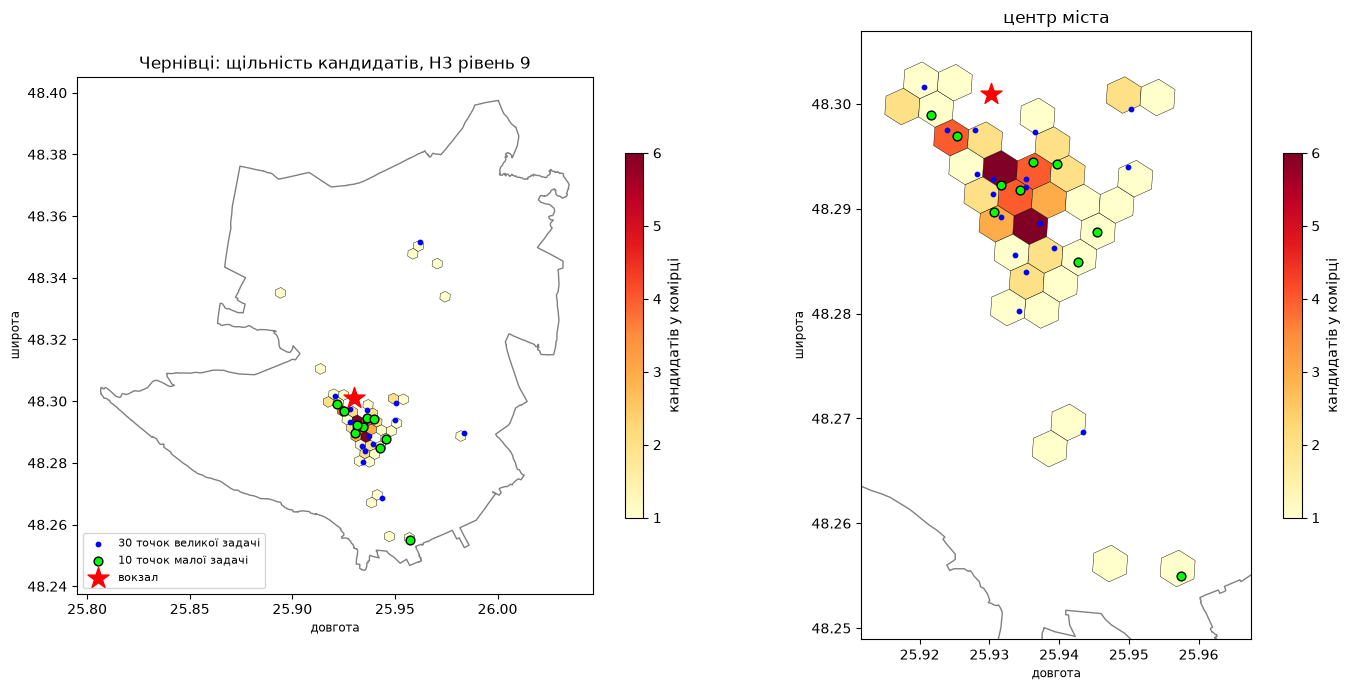

In [28]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

rp = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rp]    # (lat, lng)!
dens = cand['h3'].value_counts()
hexes = gpd.GeoDataFrame(
    {'h3': dens.index, 'n': dens.values},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens.index],
    crs='EPSG:4326')

# перевірка, що шестикутники лягли в місто, а не в океан
print('центр шестикутників усередині межі міста:', bool(poly.contains(hexes.unary_union.centroid)))
print('площа комірки ~%.3f км²' % (hexes.to_crs(32635).area.median() / 1e6))
cum = dens.cumsum() / dens.sum()
HALF_CELLS = int((cum < 0.5).sum() + 1)
print('кандидатів %d у %d комірках; половина кандидатів - у %d комірках (%.0f%% зайнятих комірок)'
      % (len(cand), len(dens), HALF_CELLS, 100 * HALF_CELLS / len(dens)))
print('найгустіша комірка: %d об’єктів' % dens.iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, zoom in zip(axes, [False, True]):
    boundary.boundary.plot(ax=ax, color='grey', lw=1)
    hexes.plot(ax=ax, column='n', cmap='YlOrRd', legend=True, edgecolor='k', lw=0.3,
               legend_kwds={'label': 'кандидатів у комірці', 'shrink': 0.6})
    pts30.plot(ax=ax, color='blue', markersize=10, label='30 точок великої задачі')
    pts10.plot(ax=ax, color='lime', edgecolor='k', markersize=40, label='10 точок малої задачі')
    pts10.iloc[[0]].plot(ax=ax, color='red', marker='*', markersize=250, label='вокзал')
    if zoom:
        x0, y0, x1, y1 = pts10.total_bounds
        ax.set_xlim(x0 - 0.01, x1 + 0.01); ax.set_ylim(y0 - 0.006, y1 + 0.006)
        ax.set_title('центр міста')
    else:
        ax.set_title('%s: щільність кандидатів, H3 рівень %d' % (CITY.split(',')[0], H3_RES))
        ax.legend(loc='lower left', fontsize=8)
    ax.set_xlabel('довгота'); ax.set_ylabel('широта')
plt.tight_layout(); plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [29]:
# обидва шари в метричну CRS, інакше відстань буде в градусах
route_m = pts10.to_crs(32635).copy()
route_m['№'] = range(len(route_m))
am_m = amenities[['name', 'amenity', 'geometry']].to_crs(32635)

near = gpd.sjoin_nearest(route_m, am_m, how='left', distance_col='відстань_м')
near = near[~near.index.duplicated(keep='first')]     # при рівних відстанях беру перший
tab = near[['№', 'name_left', 'amenity', 'name_right', 'відстань_м']].rename(
    columns={'name_left': 'точка маршруту', 'name_right': 'найближчий заклад'})
tab['відстань_м'] = tab['відстань_м'].round(1)
tab['найближчий заклад'] = tab['найближчий заклад'].fillna('(без назви)')
display(tab.set_index('№'))
print('закладів у шарі amenities:', len(amenities), amenities['amenity'].value_counts().to_dict())
print('медіана відстані до найближчого закладу: %.0f м, максимум %.0f м'
      % (tab['відстань_м'].median(), tab['відстань_м'].max()))

# для порівняння - що було б у градусах (пастка)
bad = gpd.sjoin_nearest(pts10, amenities[['geometry']], distance_col='d')
print('та сама відстань "у градусах" для першої точки: %.5f - число без сенсу' % bad['d'].iloc[0])

,точка маршруту,amenity,найближчий заклад,відстань_м
№,,,,
0,"СТАРТ: Залізничний вокзал ""Чернівці""",toilets,(без назви),33.2
1,Костел Воздвиження Святого Христа,cafe,Гауптвахта,23.7
2,Музей Володимира Івасюка,restaurant,Гарячий Чебурек,348.0
3,Музей Буковинської Діаспори,toilets,(без назви),146.5
4,Музей пожежно-рятувальної справи,drinking_water,Долина Плюс питна вода,56.8
5,Турецька криниця,restaurant,La Multi ani,130.3
6,Художній музей,cafe,Літературне кафе,10.1
7,Музей етнографії та стародавньої історії,toilets,(без назви),34.9
8,Чернівецький літературно-меморіальний музей Ол...,restaurant,Гарячий Чебурек,172.7


закладів у шарі amenities: 294 {'cafe': 137, 'restaurant': 118, 'toilets': 29, 'drinking_water': 10}
медіана відстані до найближчого закладу: 57 м, максимум 348 м
та сама відстань "у градусах" для першої точки: 0.00040 - число без сенсу


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

лінія по ребрах: 15007 м (оптимум з матриці 15094 м), вершин у лінії 352
прямі відрізки : 12469 м, вершин 12 -> дорогою довше на 21%
збережено lr5_маршрут.html


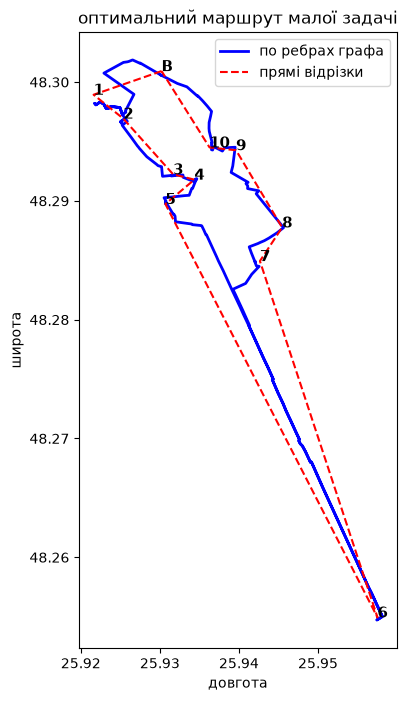

In [30]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

road_ll = route_coords(ex10, ids10)                                    # (lat, lon)
straight_ll = [(pts10.geometry.iloc[i].y, pts10.geometry.iloc[i].x) for i in ex10]

# перевірка: довжина намальованої лінії має збігатися з оптимумом із матриці
def line_len_m(latlon):
    g = gpd.GeoSeries([Point(lon, lat) for lat, lon in latlon], crs='EPSG:4326').to_crs(32635)
    return float(sum(g.iloc[k].distance(g.iloc[k + 1]) for k in range(len(g) - 1)))
L_road_drawn, L_straight = line_len_m(road_ll), line_len_m(straight_ll)
print('лінія по ребрах: %.0f м (оптимум з матриці %.0f м), вершин у лінії %d'
      % (L_road_drawn, L_opt, len(road_ll)))
print('прямі відрізки : %.0f м, вершин %d -> дорогою довше на %.0f%%'
      % (L_straight, len(straight_ll), 100 * (L_opt / L_straight - 1)))

center = pts10.geometry.union_all().centroid
fmap = folium.Map(location=[center.y, center.x], zoom_start=15, tiles=BASEMAP)
folium.PolyLine(straight_ll, color='red', weight=2, dash_array='6 6', opacity=0.9,
                tooltip='прямі відрізки: %.1f км' % (L_straight / 1000)).add_to(fmap)
folium.PolyLine(road_ll, color='blue', weight=4, opacity=0.8,
                tooltip='маршрут по ребрах графа: %.1f км' % (L_opt / 1000)).add_to(fmap)
for step, i in enumerate(ex10[:-1]):
    p = pts10.geometry.iloc[i]
    label = 'В' if i == 0 else str(step)
    color = '#c00' if i == 0 else '#1a4fa0'
    folium.Marker([p.y, p.x],
                  tooltip='%s. %s' % (label, pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html='<div style="background:%s;color:#fff;border-radius:50%%;'
                                           'width:22px;height:22px;text-align:center;line-height:22px;'
                                           'font-weight:bold;font-size:12px">%s</div>' % (color, label))
                  ).add_to(fmap)
legend = ('<div style="position:fixed;bottom:20px;left:20px;z-index:9999;background:#fff;padding:8px;'
          'border:1px solid #888;font-size:13px"><b>%s - ЛР5</b><br>'
          '<span style="color:blue">&#9473;&#9473;</span> маршрут по ребрах графа, %.2f км<br>'
          '<span style="color:red">- - -</span> прямі відрізки, %.2f км<br>'
          'Дані &copy; OpenStreetMap contributors, ODbL</div>'
          % (CITY.split(',')[0], L_opt / 1000, L_straight / 1000))
fmap.get_root().html.add_child(folium.Element(legend))
fmap.save('lr5_маршрут.html')
print('збережено lr5_маршрут.html')

# статична копія, щоб різницю було видно навіть там, де folium не відкривається
fig, ax = plt.subplots(figsize=(8, 8))
ax.plot([c[1] for c in road_ll], [c[0] for c in road_ll], color='blue', lw=2, label='по ребрах графа')
ax.plot([c[1] for c in straight_ll], [c[0] for c in straight_ll], 'r--', lw=1.5, label='прямі відрізки')
for step, i in enumerate(ex10[:-1]):
    p = pts10.geometry.iloc[i]
    ax.annotate('В' if i == 0 else str(step), (p.x, p.y), fontsize=11, weight='bold')
ax.set_aspect(1 / np.cos(np.radians(center.y)))
ax.set_xlabel('довгота'); ax.set_ylabel('широта'); ax.legend(); ax.set_title('оптимальний маршрут малої задачі')
plt.show()
fmap

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [31]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.3 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [32]:
# числа для звіту беру прямо зі змінних, щоб вони збігались з виводами вище
L_nn10, L_op10 = tour_length(D10, nn10), tour_length(D10, op10)
nn_gap, op_gap = 100 * (L_nn10 / L_opt - 1), 100 * (L_op10 / L_opt - 1)
nn_legs = [D10[nn10[k], nn10[k + 1]] for k in range(len(nn10) - 1)]
det10, det30 = detour_factor(D10, E10), detour_factor(D30, E30)
mi, mj = np.unravel_index(np.nanargmax(R10), R10.shape)
drop_txt = ', '.join('%s - %d' % (k, v) for k, v in dropped['тип'].value_counts().items())
w_txt = ', '.join('%s %.2f' % (k, v) for k, v in WEIGHTS.items())
far30 = pts30['name'].iloc[int(np.argmax(D30[0]))]
n_poly = int((cand['area_m2'] > 0).sum())
# внесок окремих переходів оптимального маршруту в різницю "дорога - пряма"
legs = list(zip(ex10[:-1], ex10[1:]))
L_straight_m = sum(E10[a, b] for a, b in legs)
leg_extra = sorted(((D10[a, b] - E10[a, b], D10[a, b] / E10[a, b]) for a, b in legs), reverse=True)
extra2 = leg_extra[0][0] + leg_extra[1][0]
legs_r = [leg_extra[0][1], leg_extra[1][1]]

REPORT = f'''
Варіант 6, місто {CITY} (зі списку, не змінювала).
Дані (c) OpenStreetMap contributors, ліцензія ODbL. Дані взяті живим запитом до Overpass один раз,
далі читаються зі знімка в теці {OUT}. Знімок усіх шарів читається за {T_SNAP:.2f} с проти {T_LIVE:.0f} с
живого запиту (у ~{T_LIVE / T_SNAP:.0f} разів швидше), і при повторному запуску не передано {MB_SAVED:.1f} МБ.

1. Об'єктів у шарі heritage: {len(heritage)}. За тегами підходять усі {int(mask.sum())}, бо запит уже був
   за historic=* або tourism із переліку. Відкинуто {len(dropped)} об'єкт(ів) без name ({drop_txt}).
   Лишилось кандидатів: {len(cand)}, типи геометрії {cand.geometry.geom_type.value_counts().to_dict()}.
   Без пояснень замовнику не віддала б: правило "немає name - викинути" відкидає і справжні
   пам'ятки, у яких назва записана не в name (напр. гробниця з description "Ohel Ruzhin", way 159474035),
   і водночас пропускає слабкі об'єкти з назвою (меморіальні дошки, "Стадіон", "Меморіальна дошка").
   Тобто фільтр технічно потрібен (маршрут не може вести до "безіменного меморіалу"), але замовник
   має знати, що частина пам'яток випала через неповну розмітку, а не через те, що вони не цінні.

2. Сигнали і ваги: {w_txt}.
   wiki має найбільшу вагу, бо статтю у Вікіпедії чи запис у Wikidata не пишуть про
   нецікаві й неважливі об'єкти - це найсильніша ознака, що об'єкт хтось визнав цінним.
   Кількість мов назви - теж ознака популярності, музей чи галерея - місце, зроблене саме
   для відвідування, historic лише відсікає сучасні об'єкти. Площа найслабша: велика площа
   буває і в офісу чи складу, а не тільки в пам'ятки, до того ж вона є лише в {n_poly}
   з {len(cand)} кандидатів. Двом об'єктам ({', '.join(WIKI_WRONG_NAMES)}) сигнал wiki
   не зарахувала: їхній wikidata веде не на пам'ятник, а на парк / сквер, де він стоїть.

3. Перетин рейтингу з рейтингом за площею: {overlap} з {N_SMALL}. З площею > 0 лише {n_poly} кандидати,
   тому решта місць у "топі за площею" - точки з площею 0, і їх порядок визначає просто id OSM.
   З рейтингом "усі ваги однакові" (ті самі сигнали) перетин {overlap_eq} з {N_SMALL}, і туди потрапляють
   "Стадіон" та "Пожежна сирена". Тобто дані одні, код без помилок, а списки різні: "найкращі" -
   це властивість обраного критерію і ваг, за які відповідає аналітик, а не властивість даних.

4. Коефіцієнт обходу (медіана дорога/пряма): {det10:.2f} на малій задачі і {det30:.2f} на великій -
   типовий для пішохідної мережі (1,2-1,6). Але розкид великий: максимум {np.nanmax(R10):.2f} для пари
   "{pts10['name'].iloc[mi]}" -> "{pts10['name'].iloc[mj]}" ({E10[mi, mj]:.0f} м прямо, {D10[mi, mj]:.0f} м дорогою).
   Асиметрія {float(np.max(np.abs(D10 - D10.T))):.0f} м, бо walk-граф osmnx має кожне ребро в обидва боки.

5. Найближчий сусід гірший за точний розв'язок на {nn_gap:.1f}% ({L_nn10:.0f} м проти {L_opt:.0f} м),
   2-opt - лише на {op_gap:.1f}% ({L_op10:.0f} м). Число здивувало: на 10 точках очікувала кілька відсотків.
   Причина видна в довжинах кроків NN: найдовший перехід {max(nn_legs):.0f} м, а останній, повернення на вокзал, -
   {nn_legs[-1]:.0f} м - жадібний метод "з'їв" близькі точки і в кінці мусить іти через пів міста.
   На великій задачі 2-opt скоротив маршрут NN з {L_nn30 / 1000:.2f} до {L_op30 / 1000:.2f} км
   ({100 * (1 - L_op30 / L_nn30):.1f}%) за {t_op30:.3f} с.

6. Точок у великій задачі: {len(ids30)} (30 пам'яток + вокзал). Таблиця Held-Karp має 2^30 * 30 =
   3,2*10^10 клітин, це {HK31_GB:.0f} ГБ при 8 байтах на клітину лише для dp (а в коді ще таблиця par,
   і Python-список займає більше 8 байт на число). Такої пам'яті немає в жодному ноутбуці, а кожні
   +5 точок множать потребу приблизно в 30 разів. Операцій ~9,7*10^11 - на 11 точках було {t_hk10:.2f} с.

7. Що виявилось неправильним (усе перевірено на openstreetmap.org і wikidata.org):
   - Хибні wikidata: "Franz Josef" (node 1400237293) веде на Q20083620 "Парк імені Юрія Федьковича",
     "Пам'ятник Сидору Воробкевичу" (node 2242145097) - на Q60174665 "Сквер з різновидностями рідкісних
     дерев". Обидва потрапляли в топ-10 лише завдяки wiki, тому сигнал wiki їм обнулила (WIKI_WRONG).
   - Дублікати: "Німецький будинок" двічі (node 6211071385 і 8015932385, 5 м, ті самі теги) - лишила один.
     "Steinbarg" і "Вуличне мистецтво" (45 м) - той самий арт-простір, лишила один.
   - Правило 60 м помиляється: "600 років моєму рідному місту" (node 5173812303, окремий пам'ятник
     2008 р.) за 54 м від костелу - не дубль, але правило його прибрало. Для маршруту це не критично
     (вони поруч, турист побачить обидва), тому правило лишила, але замовнику це треба пояснити.
   - Підозра на об'єкт не на місці: "Пам'ятник Сидіру Воробкевичу" (node 3152270478) з помилкою в імені
     стоїть за 4,7 км від центрального пам'ятника Воробкевичу. Схоже на окремий пам'ятник з опискою,
     у топ він не потрапляє, тому лишила як є.
   - Пропущені назви: гробниця "Ohel Ruzhin" у Садгорі (way 159474035) - відоме місце паломництва, але
     назва записана в description, а не в name, тому фільтр її відкинув. Обрізана назва "Черн" у historic=castle
     (node 2285800265), за координатами це, найімовірніше, руїни Цецинської фортеці.
   - Чого немає зовсім: Резиденції буковинських митрополитів (ЮНЕСКО) і Ратуші в шарі немає - вони не
     мають тегів historic/tourism з переліку. Тобто "10 найвартісніших за OSM" обходять головну пам'ятку
     міста, і замовнику треба це сказати, а не віддавати маршрут мовчки.

Додатково.
- H3: кандидатів {len(cand)}, зайнятих комірок рівня 9 - {len(dens)}, половина кандидатів - лише в {HALF_CELLS} з них
  (центр міста). Тому маршрут на 10 точках компактний, а на 30 точках змушений виходити на околиці
  (найдальша точка від вокзалу - "{far30}", {D30[0].max() / 1000:.1f} км дорогою).
- Найближчі заклади до точок маршруту: медіана {tab['відстань_м'].median():.0f} м, максимум {tab['відстань_м'].max():.0f} м.

Висновок, якого не було в завданні.
- Медіанний коефіцієнт обходу {det10:.2f} занижує реальну різницю для маршруту: оптимальний маршрут
  дорогою {L_opt / 1000:.2f} км, а по прямих між тими самими точками {L_straight / 1000:.2f} км, тобто на
  {100 * (L_opt / L_straight - 1):.0f}% більше. Із {(L_opt - L_straight_m) / 1000:.1f} км різниці {extra2 / 1000:.1f} км дають лише два переходи
  (з обходом {legs_r[0]:.1f} і {legs_r[1]:.1f}), медіана такі "хвости" не бачить. Тобто оцінювати час прогулянки
  як "пряма * 1,2" не можна, а такі переходи варто перевірити на карті: це справжня перешкода
  чи наслідок прив'язки (найдальша прив'язка точка -> вузол {dist10.max():.0f} м).
- Для туристичного застосунку 30 найкращих пам'яток міста - не піший маршрут: {L_op30 / 1000:.0f} км
  це 8-9 годин ходи без зупинок. Розумніше обмежувати радіус (напр. центр, де половина пам'яток
  лежить у {HALF_CELLS} комірках H3), а не брати топ-N по всьому місту.
- Площа як критерій для Чернівців майже не має сенсу: полігонів серед кандидатів {n_poly} з {len(cand)}.
  Щоб площа щось важила, треба брати площу будівлі, в якій стоїть точка (окремий шар будівель).

Декларація про використання ШІ:
ШІ-помічник: Claude (модель Claude Opus 5.5) у Claude Code. Що зробив ШІ: написав код у комірках
завдань (fetch, фільтр кандидатів, сигнали і формулу рейтингу із запропонованими вагами, порівняння
рейтингів, чистку дублікатів, вибір вокзалу, check_snap, матриці і коефіцієнт обходу, найближчий
сусід і 2-opt, таблицю зростання Held-Karp, H3, sjoin_nearest, карту) і чернетку цього звіту,
а також запускав ноутбук; коли Overpass відповідав 502, додав повтор запиту через дзеркала.
Окремо (поза ноутбуком) оптимум Held-Karp на малій задачі звірено з повним перебором усіх 10!
порядків обходу - довжина та сама, а 2-opt після завершення не має жодного покращуючого розвороту.
Як перевірялось (вбудовано в ноутбук, видно у виводах): CRS - estimate_utm_crs() дає 32635, усі
відстані і площі рахуються після to_crs(32635), а для порівняння показано "відстань у градусах";
порядок координат - Point(lon, lat), у folium (lat, lon), шестикутники H3 перевірено, що лежать
у межі міста; osmnx 2.x - лише features_from_polygon; є і Point, і Polygon; тест close_pairs на
двох точках за ~30 м; check_snap - різних вузлів стільки ж, скільки точок, усі в головній
компоненті графа; немає inf і нульових віддалей; самоперевірки маршрутів (старт = фініш, кожна
точка один раз, 2-opt не гірший за NN, Held-Karp не гірший за 2-opt); довжина намальованої
лінії по ребрах звірена з оптимумом з матриці; детермінованість - стабільне сортування за id,
NN при рівності бере менший номер, 2-opt без випадковості.
Що робила я: погодилась із запропонованими вагами і сформулювала, чому (wiki - про неважливі
об'єкти статей не пишуть; площа - буває великою і в офісу чи складу); вирішила не зараховувати
wiki двом об'єктам із хибним wikidata, коли ШІ показав, куди ведуть ці посилання; запускала
ноутбук у VS Code (перший запуск упав з 502 від Overpass, після чого ШІ додав повтор через дзеркала).
Знайдені проблеми з даними (питання 7) і текст звіту підготував ШІ; дані для питання 7 ШІ звірив
з openstreetmap.org і wikidata.org.
'''
print(REPORT)


Варіант 6, місто Чернівці, Україна (зі списку, не змінювала).
Дані (c) OpenStreetMap contributors, ліцензія ODbL. Дані взяті живим запитом до Overpass один раз,
далі читаються зі знімка в теці osm_чернівці. Знімок усіх шарів читається за 0.44 с проти 596 с
живого запиту (у ~1342 разів швидше), і при повторному запуску не передано 7.3 МБ.

1. Об'єктів у шарі heritage: 93. За тегами підходять усі 93, бо запит уже був
   за historic=* або tourism із переліку. Відкинуто 21 об'єкт(ів) без name (memorial - 7, tourism=attraction - 5, railway_car - 4, monument - 2, tourism=artwork - 1, tourism=viewpoint - 1, tomb - 1).
   Лишилось кандидатів: 72, типи геометрії {'Point': 68, 'Polygon': 4}.
   Без пояснень замовнику не віддала б: правило "немає name - викинути" відкидає і справжні
   пам'ятки, у яких назва записана не в name (напр. гробниця з description "Ohel Ruzhin", way 159474035),
   і водночас пропускає слабкі об'єкти з назвою (меморіальні дошки, "Стадіон", "Меморіальна дошка").
   Тобто 